# Error analysis

Where does the model lose BERTScore F1 on dev, and why? Needs the predictions file and its `.scores.jsonl` (written by `evaluate()`), plus the dev gold answers.

The released data has **no `country` / `category` fields**, so the splits below use a question-type rule and a place-name proxy, both copied from `shared/notebooks/00_EDA.ipynb`.

To analyse another run (for example Gemma or Omni), change `MODEL` and `PROMPT_ID` in the first code cell and run everything again. The run must be scored first: `01_baselines.ipynb`, section Scoring.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "shared"))
from data import RESULTS_DIR, load_jsonl, load_split, preds_path

pd.set_option("display.max_colwidth", 200)

# the run to analyse: file name is t2_text_dev_en_<MODEL>_<PROMPT_ID>.jsonl
MODEL = "Qwen3-VL-4B-Instruct"
PROMPT_ID = "gold_style_v1"
PREDS = preds_path("t2_text", "dev", MODEL, PROMPT_ID)
SCORES = PREDS.with_suffix(".scores.jsonl")
print(PREDS)

scored = sorted(f.name.removesuffix(".scores.jsonl").removeprefix("t2_text_dev_en_")
                for f in PREDS.parent.glob("t2_text_dev_en_*.scores.jsonl"))
print("scored runs (MODEL_PROMPT_ID):", *scored, sep="\n  ")

/Users/mohinska/Desktop/mmculture-qa/preds/t2_text_dev_en_Qwen3-VL-4B-Instruct_gold_style_v1.jsonl
scored runs (MODEL_PROMPT_ID):
  Qwen3-VL-4B-Instruct_gold_style_v1
  Qwen3-VL-4B-Instruct_plain
  Qwen3-VL-8B-Instruct_gold_style_v1
  Qwen3-VL-8B-Instruct_plain


In [2]:
if not PREDS.exists():
    raise FileNotFoundError(f"{PREDS} not found: put the predictions into preds/ or fix MODEL / PROMPT_ID (scored runs are listed above)")
if not SCORES.exists():
    raise FileNotFoundError(f"{SCORES} not found: run the Scoring section of 01_baselines.ipynb for this run first")

gold = pd.DataFrame(load_split("qa", "dev")).drop_duplicates("id", keep="last")  # same as evaluate(): one row per id
gold = gold[["id", "question", "answer"]].rename(columns={"answer": "gold"})
preds = pd.DataFrame(load_jsonl(PREDS)).drop_duplicates("id", keep="last")[["id", "answer"]].rename(columns={"answer": "pred"})
scores = pd.DataFrame(load_jsonl(SCORES))[["id", "p", "r", "f1"]]

df = gold.merge(preds, on="id").merge(scores, on="id")
df["pred"] = df["pred"].fillna("")
print(f"{len(df)} scored examples (the run answered {len(preds)} ids; dev has {len(gold)})")

200 scored examples (the run answered 200 ids; dev has 1000)


## 1. Overview

In [3]:
print(f"{MODEL} / {PROMPT_ID}: n={len(df)}  F1={df.f1.mean():.4f}  P={df.p.mean():.4f}  R={df.r.mean():.4f}")
print("F1 quantiles:"); display(df["f1"].describe(percentiles=[.05, .25, .5, .75, .95]).round(4).to_frame().T)

Qwen3-VL-4B-Instruct / gold_style_v1: n=200  F1=0.7915  P=0.7852  R=0.8002
F1 quantiles:


,count,mean,std,min,5%,25%,50%,75%,95%,max
f1,200.0,0.7915,0.0422,0.676,0.7231,0.7631,0.7919,0.8199,0.8591,0.9183


In [4]:
rows = [json.load(open(p)) for p in sorted(RESULTS_DIR.glob("t2_text_dev_*.json"))]
runs = pd.DataFrame([r for r in rows if "bertscore_f1" in r])   # skips results without the flat keys
if len(runs) > 1:
    display(runs[["preds", "n", "bertscore_f1", "bertscore_p", "bertscore_r", "bleu", "rouge_l"]].round(4)
            .sort_values("bertscore_f1", ascending=False))
    print("runs with different n are not directly comparable")
else:
    print("Only one run in results/, nothing to compare.")

,preds,n,bertscore_f1,bertscore_p,bertscore_r,bleu,rouge_l
0,t2_text_dev_en_Qwen3-VL-4B-Instruct_gold_style_v1.jsonl,200,0.7915,0.7852,0.8002,11.5740,0.3239
2,t2_text_dev_en_Qwen3-VL-8B-Instruct_gold_style_v1.jsonl,200,0.7880,0.7773,0.8011,11.4800,0.3289
1,t2_text_dev_en_Qwen3-VL-4B-Instruct_plain.jsonl,200,0.7322,0.6644,0.8171,3.7009,0.2323
3,t2_text_dev_en_Qwen3-VL-8B-Instruct_plain.jsonl,200,0.7252,0.6616,0.8045,3.5450,0.2105


runs with different n are not directly comparable


## 2. Answer length

,g_words,p_words
mean,26.1,24.2
median,25.0,24.0


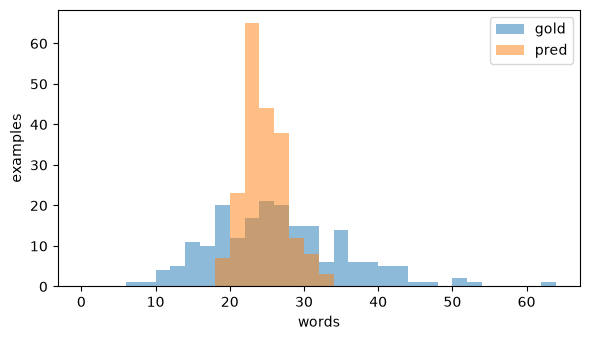

In [5]:
df["g_words"] = df["gold"].str.split().str.len()
df["p_words"] = df["pred"].str.split().str.len()
df["ratio"] = df["p_words"] / df["g_words"].clip(lower=1)
display(df[["g_words", "p_words"]].agg(["mean", "median"]).round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = range(0, int(max(df.g_words.max(), df.p_words.max())) + 3, 2)
ax.hist(df["g_words"], bins=bins, alpha=.5, label="gold")
ax.hist(df["p_words"], bins=bins, alpha=.5, label="pred")
ax.set(xlabel="words", ylabel="examples"); ax.legend()
plt.tight_layout(); plt.show()

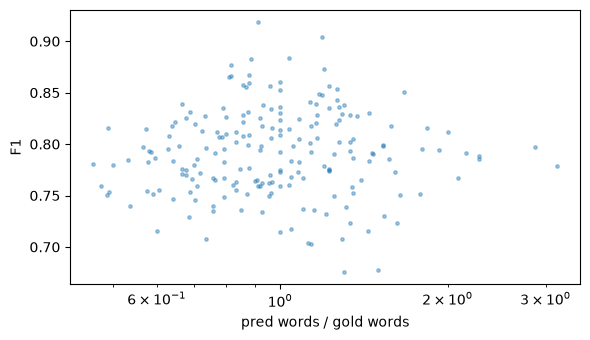

,n,mean_f1
ratio_bin,,
<0.5,6,0.7732
0.5-0.8,54,0.7828
0.8-1.25,93,0.8009
1.25-2,41,0.7853
>2,6,0.7846


In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(df["ratio"], df["f1"], s=6, alpha=.4)
ax.set(xlabel="pred words / gold words", ylabel="F1", xscale="log")
plt.tight_layout(); plt.show()

df["ratio_bin"] = pd.cut(df["ratio"], [0, .5, .8, 1.25, 2, np.inf], labels=["<0.5", "0.5-0.8", "0.8-1.25", "1.25-2", ">2"])
display(df.groupby("ratio_bin", observed=True)["f1"].agg(n="size", mean_f1="mean").round(4))

## 3. Question type

Same rule as the EDA notebook, plus the first two words of the question.

In [7]:
def qtype(q):
    q = q.lower()
    for k, pat in [("significance/meaning", r"significan|symboli|meaning|represent"), ("cultural/traditional", r"cultur|tradition|heritage"),
                   ("identify (what is/which/who)", r"^(what|which|who)\b.*\b(is|are|name|type|kind)\b")]:
        if re.search(pat, q): return k
    return "other"

df["qtype"] = df["question"].map(qtype)
display(df.groupby("qtype")["f1"].agg(n="size", mean_f1="mean").round(4))

,n,mean_f1
qtype,,
cultural/traditional,25,0.7952
identify (what is/which/who),86,0.7855
other,21,0.7993
significance/meaning,68,0.7952


In [8]:
df["opening"] = df["question"].str.split().str[:2].str.join(" ")
top = df.groupby("opening")["f1"].agg(n="size", mean_f1="mean").round(4)
display(top[top["n"] >= 10].sort_values("n", ascending=False).head(10))

,n,mean_f1
opening,,
What is,46,0.7951
What type,23,0.7724
What architectural,22,0.8055
What cultural,17,0.8072
What are,12,0.7918
What does,12,0.7957
What types,11,0.8177


## 4. Place-name proxy for country

There is no country field. The proxy is the list of country and city names from the EDA notebook, matched in the **gold** answer (the question alone rarely names the place). It is a rough guess: unmatched examples may still be about some country, and one example can name several.

In [9]:
PLACES = {
    "Egypt": ["egypt", "cairo", "giza", "luxor", "alexandria", "aswan"],
    "UAE": ["uae", "emirat", "dubai", "abu dhabi", "sharjah"],
    "Saudi Arabia": ["saudi", "riyadh", "mecca", "makkah", "medina", "jeddah"],
    "Qatar": ["qatar", "doha"], "Bahrain": ["bahrain", "manama"], "Kuwait": ["kuwait"],
    "Oman": ["oman", "muscat"], "Yemen": ["yemen", "sanaa", "aden"],
    "Iraq": ["iraq", "baghdad", "mosul", "najaf", "karbala", "basra", "erbil"],
    "Syria": ["syria", "damascus", "aleppo", "palmyra"],
    "Lebanon": ["leban", "beirut", "byblos", "baalbek"], "Jordan": ["jordan", "amman", "petra"],
    "Palestine": ["palestin", "gaza", "jerusalem", "ramallah", "bethlehem"],
    "Morocco": ["morocc", "marrakech", "fez", "casablanca", "rabat"],
    "Algeria": ["alger", "algiers"], "Tunisia": ["tunis"], "Libya": ["libya", "tripoli", "benghazi"],
    "Sudan": ["sudan", "khartoum"],
}
def guess_countries(text):
    t = text.lower()
    return [c for c, keys in PLACES.items() if any(re.search(r"\b" + re.escape(k), t) for k in keys)]

df["countries"] = df["gold"].map(guess_countries)
df["names_place"] = df["countries"].str.len() > 0
display(df.groupby("names_place")["f1"].agg(n="size", mean_f1="mean").round(4))

,n,mean_f1
names_place,,
False,134,0.7913
True,66,0.7919


In [10]:
by_country = df.explode("countries").dropna(subset=["countries"]).groupby("countries")["f1"].agg(n="size", mean_f1="mean").round(4)
display(by_country[by_country["n"] >= 5].sort_values("mean_f1"))

,n,mean_f1
countries,,
Saudi Arabia,7,0.7658
Palestine,6,0.7809
Jordan,8,0.7861
UAE,6,0.7887
Oman,5,0.7963
Morocco,7,0.8136
Egypt,5,0.8186


## 5. Worst 20 answers

Tag each with one label:

- `wrong entity`: names a different landmark, dish, person or country than the gold.
- `right entity but generic`: the entity is right, but the answer is vague or lacks the cultural detail.
- `too long`: far longer than gold (extra sentences, explanations).
- `refusal`: says it cannot tell, or declines to answer.
- `correct, different detail`: matches the gold in substance, but the words differ or it adds a detail the gold does not have (for example a guessed place).
- `other`: anything else (note why in a comment).

In [11]:
worst = df.nsmallest(20, "f1")[["id", "question", "gold", "pred", "f1"]].reset_index(drop=True)
worst["tag"] = ""
display(worst.drop(columns="id").round(3))

,question,gold,pred,f1,tag
0,"What type of technology is used in camel racing as seen in this image, and why is it significant?","Robotic jockeys are used in camel racing, replacing human jockeys for safety and ethical reasons, especially for child labor concerns.","The camels shown are equipped with harnesses and riders using traditional gear, not modern technology. This reflects ancient, culturally rooted racing practices, emphasizing heritage over innovation.",0.676,
1,What event is likely being celebrated in this nighttime street scene?,"The scene likely depicts celebrations for Saudi National Day, as people are holding Saudi Arabian flags and wearing traditional attire.","The Saudi Arabia flags and ""Vision 2030"" text suggest celebration of national development goals. This likely marks a major milestone or public event tied to Saudi Arabia's Vision 2030 initiative.",0.678,
2,"What type of unique trees are shown in the image, and where are they commonly found?","The trees shown in the image are bottle-shaped Adenium obesum trees, commonly found in the rocky desert landscapes of Socotra Island, Yemen.","The baobab trees shown are native to arid regions of Africa, particularly Madagascar and the Horn of Africa, where they symbolize resilience and cultural heritage.",0.703,
3,"What sport is being played in the image, and what clues from the image help identify it?","The sport being played is soccer. Clues include the player's uniform, the grass field, and the player's running posture, which are typical in soccer matches.","The football player wears a national team jersey with the number 20, running on a grass pitch with stadium seating in the background, indicating a professional football match.",0.703,
4,"What ancient civilization is most closely associated with the pyramids shown in this desert landscape, and what was their primary purpose?","The pyramids in this image are most closely associated with the Kingdom of Kush, specifically the Nubian civilization in present-day Sudan. Their primary purpose was to serve as royal tombs for ki...","The pyramids shown are likely from ancient Egypt, built as tombs for pharaohs to ensure their safe passage to the afterlife, reflecting deep religious beliefs.",0.708,
5,What is the primary function of the ship shown in the image?,"The ship is primarily used for cargo transportation, as indicated by its design and large hull space.","The ship shown is a Bahri Jeddah ferry, likely transporting vehicles and passengers between Saudi ports, reflecting regional maritime trade and connectivity.",0.708,
6,What architectural elements in the image suggest the town’s historical significance?,"The image features fortified walls, whitewashed buildings, and a minaret, all of which are indicative of a historic town with Islamic and Mediterranean architectural influences.","The town’s fortified walls and tower suggest historical defense importance, likely dating to medieval times, reflecting its strategic coastal role in regional trade and defense.",0.715,
7,"What landmark is featured in the image, and what event is taking place?","The Kuwait Towers are featured in the image, and a laser light show is taking place.","The landmarks shown are the Dubai Frame, illuminated during a laser light show on February 28, 2023, celebrating cultural heritage and modern spectacle.",0.716,
8,What is the significance of the rock-cut architecture depicted in the image?,"The rock-cut architecture is part of Petra, an ancient city in Jordan that served as a major trading hub and is now recognized as a UNESCO World Heritage Site for its historical and cultural impor...","The rock-cut architecture depicted is Petra’s ancient tomb, symbolizing Nabataean ingenuity and religious devotion, carved into sandstone cliffs for elite burial.",0.716,
9,What architectural features in the image suggest that the building is a mosque or shrine?,"The domed towers, arched windows, intricate designs, and the presence of a flag are all char

In [12]:
# copy this printout into the next cell and fill in a tag per id
print("TAGS = {")
for i, r in worst.iterrows():
    print(f'    "{r.id}": "",  # {i}')
print("}")

TAGS = {
    "4ac4052a1045c0d225ebab854de1795edc65e3d4f4cdffcd67a65d33750e412e": "",  # 0
    "f32dfa085da00d97ac6381cfeb5ff9d9983890de4e44088649a6d2a5c145405e": "",  # 1
    "24c1c53333a8edecd4b53dc55cfab7ee5e0db55e6b9795488cda4cb45cf7da42": "",  # 2
    "66fdb9c7e3247496afa8fc483905dff28cb0402facc0796ed9aaea0f3ebd73ab": "",  # 3
    "2dd27f5633632d45a6f9a2200fac25d6055213cf1f7c31c08951d3ae4d7ce824": "",  # 4
    "be09ee278bf4f3bc4705df828990b3aa9eb4261a65f118159e746047eef0a653": "",  # 5
    "1edd597d03ec8551f190a91df351db26d5953d60fa3c56993232fdcb121b76cd": "",  # 6
    "fc4c228c490075adcb279b07f6df9e3d68abc82c42baf504c9e7e8ff1342e672": "",  # 7
    "4ff3a5e83a4d06772b2529454f593ec7ab7aa39c7f65a35adc0de9c8f58cbbd5": "",  # 8
    "802f68669922c70ad0b8952a7fceeea2a1e4cecadd3d741c831706a95818b7cf": "",  # 9
    "db9f1d52fd63e9fbe450da99722fe086b98fd2f346d0dc449a3234a73522b76c": "",  # 10
    "aee683e79a0bdbf31d30eb0e9b80ad2ef18efb8af63724b07777e4adc9a02e59": "",  # 11
    "b05305ca5005

In [15]:
VOCAB = ["wrong entity", "right entity but generic", "correct, different detail", "too long", "refusal", "other"]
TAGS = {
    "4ac4052a1045c0d225ebab854de1795edc65e3d4f4cdffcd67a65d33750e412e": "wrong entity",  # 0 gold: robotic jockeys, pred: no technology
    "f32dfa085da00d97ac6381cfeb5ff9d9983890de4e44088649a6d2a5c145405e": "wrong entity",  # 1 Saudi National Day vs Vision 2030 event
    "24c1c53333a8edecd4b53dc55cfab7ee5e0db55e6b9795488cda4cb45cf7da42": "wrong entity",  # 2 Adenium (Socotra) vs baobab (Africa)
    "66fdb9c7e3247496afa8fc483905dff28cb0402facc0796ed9aaea0f3ebd73ab": "correct, different detail",  # 3 soccer = football, jersey details
    "2dd27f5633632d45a6f9a2200fac25d6055213cf1f7c31c08951d3ae4d7ce824": "wrong entity",  # 4 Kush/Sudan vs Egypt
    "be09ee278bf4f3bc4705df828990b3aa9eb4261a65f118159e746047eef0a653": "wrong entity",  # 5 cargo ship vs passenger ferry
    "1edd597d03ec8551f190a91df351db26d5953d60fa3c56993232fdcb121b76cd": "right entity but generic",  # 6 misses whitewashed buildings, minaret
    "fc4c228c490075adcb279b07f6df9e3d68abc82c42baf504c9e7e8ff1342e672": "wrong entity",  # 7 Kuwait Towers vs Dubai Frame
    "4ff3a5e83a4d06772b2529454f593ec7ab7aa39c7f65a35adc0de9c8f58cbbd5": "right entity but generic",  # 8 Petra right, misses UNESCO / trade hub
    "802f68669922c70ad0b8952a7fceeea2a1e4cecadd3d741c831706a95818b7cf": "correct, different detail",  # 9 mosque features right, adds guess "India"
    "db9f1d52fd63e9fbe450da99722fe086b98fd2f346d0dc449a3234a73522b76c": "correct, different detail",  # 10 currency exchange = banknote exchange
    "aee683e79a0bdbf31d30eb0e9b80ad2ef18efb8af63724b07777e4adc9a02e59": "wrong entity",  # 11 Zamzam vs tap water
    "b05305ca50056da033eed7a9c642f8f80ee641b7661ea4f4ef84466ef8883fe1": "correct, different detail",  # 12 craftsmanship, adds metalwork / blades
    "0cc134de30262363131c0de5b2b3def1d21f5c2550e2f04d03817cf5983c9069": "correct, different detail",  # 13 activities right, adds guess "Marrakech"
    "3994a3d0dabf42f933e912a510137a8939190366989886eae532a838bdb66f05": "correct, different detail",  # 14 activities right, adds guess "Wadi Rum"
    "f4222e89572b579b35294ad75fff196bf0b9099a3b1e190e9f48c994ba38230c": "correct, different detail",  # 15 clay oven vs tandoor (a clay oven)
    "0158168f5a9be42112110d5ae47df2727c72c8689bfbfecffd829afc85d4a93d": "wrong entity",  # 16 horse riding vs camel racing
    "3d36047fc97d5b7b90ea8bcfb7fe128e2d5ca438e5ae55078df9db46c51b6285": "correct, different detail",  # 17 features right, adds guess Mesopotamian / Persian
    "26071129e133db2c20c7db173737ca35edbe8e6ece7033044a6e9109bcdfeb3a": "wrong entity",  # 18 setting: rural community vs Iran / Afghanistan
    "e2e4c2d94e36ef3f0d54a6ba6b4931341703ddd2d8f421b8cdd96c18e53a1ebe": "correct, different detail",  # 19 stone houses right, different features
}

bad = {i: t for i, t in TAGS.items() if t not in VOCAB}
assert not bad, f"unknown tags (use one of {VOCAB}): {bad}"
worst["tag"] = worst["id"].map(TAGS).fillna("untagged")
display(worst["tag"].value_counts().to_frame("count"))

,count
tag,
wrong entity,9
"correct, different detail",9
right entity but generic,2


## 6. Best 5 answers (midterm examples)

In [14]:
for _, r in df.nlargest(5, "f1").iterrows():
    print(f"F1 {r.f1:.3f}\nQ:    {r.question}\nGold: {r.gold}\nPred: {r.pred}\n")

F1 0.918
Q:    What types of teas are displayed in the image, and what ingredients are commonly used in these blends?
Gold: The teas displayed include Sultan Tea, Relax Tea, Jasmine Tea, Pomegranate Flower Tea, Stomach Tea, Flu and Cough Tea, Apple and Cinnamon Tea, and Pomegranate Tea. Common ingredients include dried fruits, flowers, herbs, and spices.
Pred: The teas displayed include Sultan, Relax, Jasmine, Pomegranate Flower, Stomach, Flu and Cough, Apple and Cinnamon, and Pomegranate blends, using dried flowers, herbs, citrus, and spices common in Middle Eastern tea traditions.

F1 0.904
Q:    What is the significance of the red flag with a crescent and star seen atop the building in this image?
Gold: The red flag with a crescent and star is the national flag of Tunisia, symbolizing the country's identity and Islamic heritage.
Pred: The red flag with crescent and star atop the building signifies Tunisia’s national identity, symbolizing its Islamic heritage and unity under the coun